# ДЗ 2. Классификация состояния автомобиля (Craigslist, Калифорния)

Делаем примерно то же самое, что на лекции в ноутбуках "Оценка стоимости квартиры" и "19-02. Adult"
(https://github.com/NikolaiZolotykh/MachineLearningCourse). Выбор датасета - в ДЗ 1.

In [1]:
import numpy as np              # Одномерные и многомерные массивы (array)
import pandas as pd             # Таблицы и временные ряды (dataframe, series)
import matplotlib.pyplot as plt # Научная графика
import seaborn as sns           # Еще больше красивой графики для визуализации данных
import sklearn                  # Алгоритмы машинного обучения
from pathlib import Path

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Found unknown categories')
pd.set_option('display.max_columns', 30)

print('numpy', np.__version__, '| pandas', pd.__version__, '| sklearn', sklearn.__version__)

numpy 2.5.3 | pandas 3.0.5 | sklearn 1.9.1


## 0. Постановка задачи

Датасет Used Cars Dataset с Kaggle (https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data) - это объявления
о продаже подержанных машин с сайта craigslist.org (США, апрель-май 2021). Как и в ДЗ 1, берем только Калифорнию.

Для каждой машины есть цена, год, марка и модель, пробег, топливо, коробка, привод, тип кузова, цвет,
статус документов, координаты и текст объявления. Нужно по этим данным предсказать состояние машины `condition`,
которое указывает продавец. Значений 6:

salvage (битая / на запчасти), fair (удовлетворительное), good (хорошее), excellent (отличное), like new (как новая), new (новая).

То есть это задача классификации с $K = 6$ классами. Классы на самом деле упорядочены, но решать будем
как обычную многоклассовую классификацию. Практический смысл - подсказывать продавцу состояние при подаче объявления
или находить объявления, где состояние явно не соответствует остальному (например, like new с пробегом 300 тыс. миль).

Качество, как на лекции, меряем долей ошибок на обучающей и тестовой выборке. Так как классы несбалансированы,
еще смотрим матрицы рассогласования, balanced accuracy (средняя по классам полнота) и macro-F1.

## 1. Загружаем данные

Полный vehicles.csv весит около 1.4 Гб (426 880 объявлений по всем штатам), поэтому при первом запуске читаем его кусками,
оставляем Калифорнию и сохраняем в vehicles_ca.csv. Дальше читается уже он. Если полного файла нет, скачиваем через kagglehub, как в ДЗ 1.
Данные лежат в общей папке `../craigslist_dataset`, в гит они не заливаются (слишком большие).

In [2]:
DATA_DIR  = Path('../craigslist_dataset')
FULL_FILE = DATA_DIR / 'vehicles.csv'
CA_FILE   = DATA_DIR / 'vehicles_ca.csv'

if not CA_FILE.exists():
    if not FULL_FILE.exists():
        import kagglehub, shutil
        downloaded = Path(kagglehub.dataset_download('austinreese/craigslist-carstrucks-data'))
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        shutil.copy(downloaded / 'vehicles.csv', FULL_FILE)
    chunks = pd.read_csv(FULL_FILE, chunksize=100_000)
    pd.concat(ch[ch['state'] == 'ca'] for ch in chunks).to_csv(CA_FILE, index=False)

data_raw = pd.read_csv(CA_FILE)
data_raw.shape

(50614, 26)

In [3]:
data_raw.head()

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
0,7316895739,https://bakersfield.craigslist.org/ctd/d/baker...,bakersfield,https://bakersfield.craigslist.org,16990,2018.0,hyundai,accent se sedan 4d,good,NaN,gas,16930.0,clean,other,3KPC24A37JE034842,fwd,NaN,sedan,white,https://images.craigslist.org/00k0k_2G5SBDPenD...,Carvana is the safer way to buy a car During t...,NaN,ca,35.380000,-119.020000,2021-05-04T12:41:15-0700
1,7316894967,https://bakersfield.craigslist.org/cto/d/tehac...,bakersfield,https://bakersfield.craigslist.org,3700,2004.0,toyota,highlander,good,6 cylinders,gas,142000.0,clean,automatic,NaN,NaN,NaN,NaN,NaN,https://images.craigslist.org/01313_dTUjBqHGgj...,"Runs Good,Brand New Tires,Tags are Current til...",NaN,ca,35.132200,-118.449000,2021-05-04T12:40:04-0700
2,7316889135,https://bakersfield.craigslist.org/ctd/d/fonta...,bakersfield,https://bakersfield.craigslist.org,0,2019.0,mercedes-benz,sprinter box truck,NaN,NaN,diesel,4074.0,clean,automatic,WDAPF4CDXKN025578,rwd,NaN,NaN,white,https://images.craigslist.org/00A0A_ivQ82zhG83...,2019 Mercedes-Benz Sprinter Box Truck RWD 6...,NaN,ca,34.070311,-117.446303,2021-05-04T12:30:16-0700
3,7316887125,https://bakersfield.craigslist.org/ctd/d/bloom...,bakersfield,https://bakersfield.craigslist.org,11975,2003.0,harley-davidson,davidson,excellent,8 cylinders,gas,207000.0,clean,automatic,NaN,rwd,full-size,pickup,black,https://images.craigslist.org/00F0F_eEBhgvA15M...,MANAGER'S SPECIAL!!! *****💰💰💰🤑 >HUGE TAX SALE...,NaN,ca,34.070612,-117.383384,2021-05-04T12:26:43-0700
4,7316876945,https://bakersfield.craigslist.org/ctd/d/victo...,bakersfield,https://bakersfield.craigslist.org,0,2014.0,nissan,rogue,NaN,NaN,gas,47287.0,clean,automatic,5N1AT2MT9EC819313,fwd,full-size,SUV,white,https://images.craigslist.org/00h0h_dSFkwIRrwz...,Vehicle DescriptionOur great-looking 2014 Niss...,NaN,ca,34.480200,-117.408200,2021-05-04T12:09:44-0700


In [4]:
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 50614 entries, 0 to 50613
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            50614 non-null  int64  
 1   url           50614 non-null  str    
 2   region        50614 non-null  str    
 3   region_url    50614 non-null  str    
 4   price         50614 non-null  int64  
 5   year          50498 non-null  float64
 6   manufacturer  48559 non-null  str    
 7   model         49995 non-null  str    
 8   condition     33104 non-null  str    
 9   cylinders     30013 non-null  str    
 10  fuel          50547 non-null  str    
 11  odometer      49456 non-null  float64
 12  title_status  48994 non-null  str    
 13  transmission  50379 non-null  str    
 14  VIN           33525 non-null  str    
 15  drive         34811 non-null  str    
 16  size          13801 non-null  str    
 17  type          41079 non-null  str    
 18  paint_color   33828 non-null  str    

Столбцы:

- `id`, `url`, `region_url`, `image_url` - id объявления и ссылки
- `region` - регион craigslist, где размещено объявление
- `price` - цена в долларах
- `year` - год выпуска
- `manufacturer`, `model` - марка и модель
- `condition` - состояние (это и предсказываем)
- `cylinders` - число цилиндров ('4 cylinders', '6 cylinders', ..., 'other')
- `fuel` - топливо (gas, diesel, hybrid, electric, other)
- `odometer` - пробег в милях
- `title_status` - статус документов (clean, salvage, rebuilt, lien, missing, parts only)
- `transmission` - коробка (automatic, manual, other)
- `VIN` - VIN номер
- `drive` - привод (fwd, rwd, 4wd)
- `size` - размер (sub-compact, compact, mid-size, full-size)
- `type` - тип кузова (sedan, SUV, pickup, ...)
- `paint_color` - цвет
- `description` - текст объявления
- `county`, `state` - округ и штат
- `lat`, `long` - координаты
- `posting_date` - дата публикации

Посмотрим на целевой признак:

In [5]:
data_raw['condition'].value_counts(dropna=False)

condition
NaN          17510
excellent    16902
good         12789
like new      2428
fair           757
new            126
salvage        102
Name: count, dtype: int64

Примерно у трети объявлений состояние не указано. Для обучения и проверки они не подходят (нет правильного ответа),
поэтому выкидываем их.

In [6]:
data = data_raw[data_raw['condition'].notna()]
data.shape

(33104, 26)

### Лишние столбцы и дубликаты

In [7]:
print('county: доля пропусков =', data['county'].isna().mean())
print('state: значения =', data['state'].unique())
print('posting_date: от', data['posting_date'].min(), 'до', data['posting_date'].max())
print('Уникальных значений: VIN =', data['VIN'].nunique(), ', model =', data['model'].nunique(),
      ', region =', data['region'].nunique())

county: доля пропусков = 1.0
state: значения = <StringArray>
['ca']
Length: 1, dtype: str
posting_date: от 2021-04-04T00:10:40-0700 до 2021-05-04T13:50:18-0700
Уникальных значений: VIN = 10473 , model = 6513 , region = 29


Что удаляем и почему:

- `id`, `url`, `region_url`, `image_url`, `VIN` - идентификаторы, к состоянию отношения не имеют;
- `county` пустой целиком, `state` везде 'ca';
- `posting_date` - все объявления за один месяц, дата тут ни на что не влияет (на лекции так же выкинули `Date`);
- `description` - текст, с ним в этом задании не работаем (можно было бы попробовать TF-IDF);
- `model` - больше 6 тыс. разных значений, записанных как попало ('f-150', 'F150 XLT', ...), после one-hot получились бы тысячи признаков;
- `region` - 29 регионов, но местоположение и так есть в `lat`, `long`.

Перед этим надо разобраться с дубликатами. Дилеры часто выкладывают одну и ту же машину по несколько раз,
причем сразу в нескольких регионах (координаты при этом разные). Если копии одной машины попадут и в train, и в test,
ошибка на тесте получится заниженной - kNN просто найдет ту же самую машину. Поэтому дубликатом считаю объявление,
совпадающее с другим по всем характеристикам машины, без учета региона и координат. Плюс убираю повторы по VIN там, где он есть.

In [8]:
car_cols = ['price', 'year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel',
            'odometer', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color']
print('Полные дубликаты (с регионом и координатами):', data.duplicated(subset=car_cols + ['region', 'lat', 'long']).sum())
print('Та же машина без учета региона и координат:  ', data.duplicated(subset=car_cols).sum())

Полные дубликаты (с регионом и координатами): 4044
Та же машина без учета региона и координат:   11989


In [9]:
data = data.drop_duplicates(subset=car_cols)
vin_dup = data['VIN'].notna() & data.duplicated(subset=['VIN'])
print('Повторы по VIN:', vin_dup.sum())
data = data[~vin_dup]
data.shape

Повторы по VIN: 555


(20560, 26)

Ушло больше трети объявлений. Сначала я удалял только полные дубликаты (4 тыс. строк), и тогда ошибка kNN на тесте была около 27%,
а у случайного леса около 20%. После нормального удаления копий получается около 34% и 27%, так что первые цифры были завышены
за счет утечки.

### Тип продавца

В ссылке `url` есть раздел сайта: `/cto/` - "cars & trucks - by owner" (продает владелец), `/ctd/` - "by dealer" (дилер).
Как дальше будет видно, дилеры и частники ставят состояние по-разному, так что сделаем из этого признак `seller`.

In [10]:
data['seller'] = data['url'].str.extract(r'/(ct[od])/')[0].map({'cto': 'owner', 'ctd': 'dealer'})
data['seller'].value_counts(dropna=False)

seller
dealer    11633
owner      8927
Name: count, dtype: int64

In [11]:
data = data.drop(['id', 'url', 'region_url', 'image_url', 'VIN', 'county', 'state',
                  'posting_date', 'description', 'model', 'region'], axis=1)
data.shape

(20560, 16)

`cylinders` по смыслу числовой признак, вытащим из строки число ('other' станет пропуском):

In [12]:
data['cylinders'].value_counts(dropna=False)

cylinders
4 cylinders     5568
NaN             5474
6 cylinders     5273
8 cylinders     3845
5 cylinders      144
other            105
10 cylinders      73
3 cylinders       49
12 cylinders      29
Name: count, dtype: int64

In [13]:
data['cylinders'] = pd.to_numeric(data['cylinders'].str.extract(r'(\d+)')[0])
data['cylinders'].value_counts(dropna=False)

cylinders
NaN     5579
4.0     5568
6.0     5273
8.0     3845
5.0      144
10.0      73
3.0       49
12.0      29
Name: count, dtype: int64

Как на лекции, строковые признаки переводим в тип category:

In [14]:
numerical_columns   = ['price', 'year', 'cylinders', 'odometer', 'lat', 'long']
categorical_columns = ['seller', 'manufacturer', 'fuel', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color']
for c in categorical_columns:
    data[c] = data[c].astype('category')

# классы от худшего к лучшему, в таком порядке рисуем графики
classes = ['salvage', 'fair', 'good', 'excellent', 'like new', 'new']
data.dtypes

price              int64
year             float64
manufacturer    category
condition            str
cylinders        float64
fuel            category
odometer         float64
title_status    category
transmission    category
drive           category
size            category
type            category
paint_color     category
lat              float64
long             float64
seller          category
dtype: object

In [15]:
N, d = len(data), data.shape[1] - 1
print(f'N = {N}, d = {d} ({len(numerical_columns)} числовых, {len(categorical_columns)} категориальных), '
      f'K = {data["condition"].nunique()}')

N = 20560, d = 15 (6 числовых, 9 категориальных), K = 6


## 2. Разбиваем на обучающую и тестовую выборки

Делим 75% / 25%. Классы несбалансированы, поэтому разбиение стратифицированное (`stratify=y`), иначе редких классов
new и salvage в тесте может оказаться совсем мало.

Дальше все (анализ, пороги для выбросов, медианы, параметры нормализации) считаем только по обучающей выборке,
чтобы не подглядывать в тест.

In [16]:
from sklearn.model_selection import train_test_split

X = data.drop('condition', axis=1)
y = data['condition']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

N_train, _ = X_train.shape
N_test,  _ = X_test.shape
N_train, N_test

(15420, 5140)

In [17]:
pd.DataFrame({'train': y_train.value_counts(normalize=True),
              'test':  y_test.value_counts(normalize=True)}).loc[classes].round(4)

,train,test
condition,,
salvage,0.0047,0.0047
fair,0.0356,0.0356
good,0.3846,0.3846
excellent,0.4794,0.4796
like new,0.0900,0.0899
new,0.0056,0.0056


## 3. Визуализация и основные характеристики

In [18]:
train = X_train.join(y_train)
train.describe()

,price,year,cylinders,odometer,lat,long
count,1.542000e+04,15420.000000,11231.000000,1.526100e+04,15376.000000,15376.000000
mean,8.821852e+04,2008.701751,5.783724,1.028144e+05,36.170868,-118.094051
std,8.947663e+06,12.182752,1.619771,1.847819e+05,2.438264,8.073432
min,0.000000e+00,1900.000000,3.000000,0.000000e+00,-37.029731,-131.923828
25%,5.995000e+03,2005.000000,4.000000,4.052800e+04,33.880000,-121.422557
50%,1.199500e+04,2012.000000,6.000000,9.097100e+04,36.319555,-119.756897
75%,2.250000e+04,2016.000000,8.000000,1.420000e+05,38.408900,-117.891262
max,1.111111e+09,2022.000000,12.000000,1.000000e+07,57.970271,139.691700


Сразу видно, что в данных много мусора:

- `price` от 0 до 1.1 млрд долларов, среднее 88 тыс. при медиане 12 тыс. - огромные выбросы;
- `odometer` до 10 млн миль - явно ошибка или заглушка;
- `year` от 1900 до 2022, медиана 2012;
- `lat` доходит до -37, `long` до 139.7 - это вообще не Калифорния;
- `cylinders` в основном 4, 6 или 8, примерно у 27% не указан.

In [19]:
train.describe(include=['category'])

,manufacturer,fuel,title_status,transmission,drive,size,type,paint_color,seller
count,14684,15419,14934,15420,11323,6092,12990,11658,15420
unique,40,5,6,3,3,4,13,12,2
top,ford,gas,clean,automatic,fwd,full-size,sedan,white,dealer
freq,1959,13234,14199,11780,4596,3071,4069,3264,8721


Чаще всего встречаются ford, бензин (86%), автомат, документы clean (95%), седан, белый цвет. Дилеров около 57%.
У `size`, `drive`, `paint_color`, `type` много незаполненных значений.

### Целевой признак

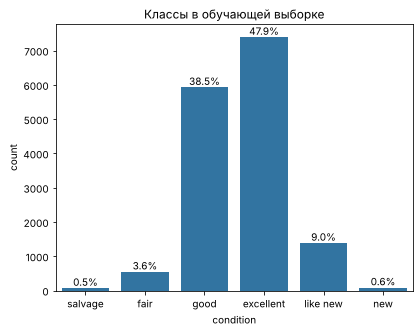

In [20]:
counts = y_train.value_counts().loc[classes]
ax = sns.countplot(x=y_train, order=classes)
for i, v in enumerate(counts):
    ax.text(i, v, f'{v / N_train:.1%}', ha='center', va='bottom')
plt.title('Классы в обучающей выборке')
pass

In [21]:
print('Самый частый класс / самый редкий:', round(counts.max() / counts.min(), 1))

Самый частый класс / самый редкий: 102.7


Классы сильно несбалансированы: excellent 48% и good 38%, like new 9%, fair 3.6%, new и salvage примерно по 0.5%
(около 80 объектов каждого в train). Если всегда отвечать excellent, ошибка будет около 50%, это и есть минимальный уровень,
который надо побить. Ну и продавцы явно себя приукрашивают - fair и salvage вместе меньше 5%.

### Распределения числовых признаков

In [22]:
train[numerical_columns].quantile([0, .005, .01, .05, .25, .5, .75, .95, .99, .995, 1])

,price,year,cylinders,odometer,lat,long
0.000,0.000000e+00,1900.0,3.0,0.0,-37.029731,-131.923828
0.005,0.000000e+00,1947.0,4.0,0.0,32.617244,-124.150883
0.010,0.000000e+00,1956.0,4.0,1.0,32.673648,-124.076500
0.050,4.453000e+02,1987.0,4.0,5484.0,32.860000,-122.415728
0.250,5.995000e+03,2005.0,4.0,40528.0,33.880000,-121.422557
0.500,1.199500e+04,2012.0,6.0,90971.0,36.319555,-119.756897
0.750,2.250000e+04,2016.0,8.0,142000.0,38.408900,-117.891262
0.950,4.098800e+04,2019.0,8.0,220500.0,39.646298,-113.957192
0.990,6.699500e+04,2020.0,8.0,297096.0,40.796675,-84.411811
0.995,8.500000e+04,2021.0,10.0,358738.5,41.322675,-84.411811


Ящики с усами для цены и пробега из-за выбросов ничего не показывают:

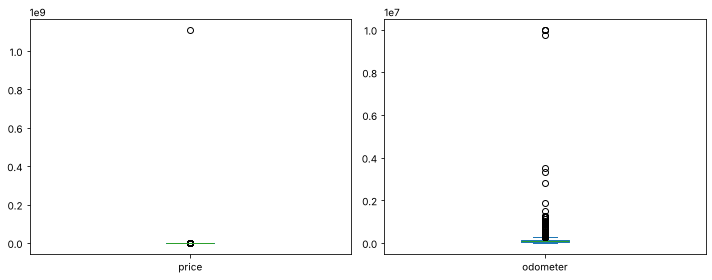

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
train['price'].plot(kind='box', ax=axes[0])
train['odometer'].plot(kind='box', ax=axes[1])
plt.tight_layout()
pass

Гистограммы, обрезанные по разумному диапазону:

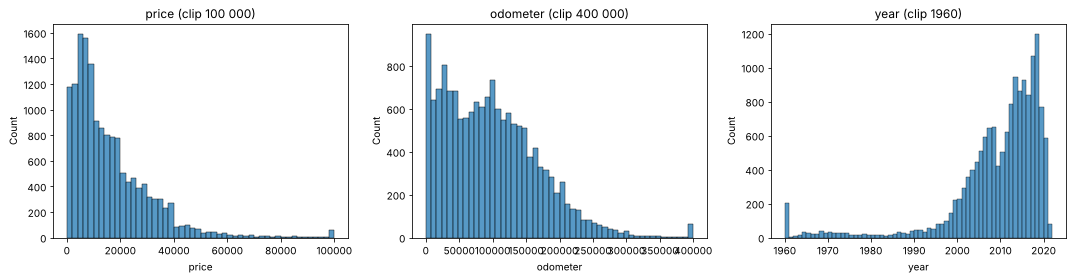

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(train['price'].clip(upper=100_000), bins=50, ax=axes[0])
axes[0].set_title('price (clip 100 000)')
sns.histplot(train['odometer'].clip(upper=400_000), bins=50, ax=axes[1])
axes[1].set_title('odometer (clip 400 000)')
sns.histplot(train['year'].clip(lower=1960), bins=62, ax=axes[2])
axes[2].set_title('year (clip 1960)')
plt.tight_layout()
pass

Цена скошена вправо и есть пик около нуля (нулевые цены). Пробег тоже скошен вправо, в основном до 200 тыс. миль, и тоже есть пик в нуле.
Год наоборот скошен влево: в основном машины 2005-2019, но есть хвост из старых коллекционных.

### Числовые признаки по классам

In [25]:
train.groupby('condition', observed=True)[numerical_columns].median().loc[classes]

,price,year,cylinders,odometer,lat,long
condition,,,,,,
salvage,3000.0,2005.0,4.0,141000.0,36.691820,-120.497500
fair,3000.0,1999.0,6.0,159000.0,36.696400,-119.894939
good,15590.0,2013.0,6.0,75000.0,35.380000,-119.186897
excellent,11000.0,2012.0,6.0,98000.0,36.815675,-119.803677
like new,12999.5,2013.0,6.0,71297.0,36.238970,-119.699919
new,27000.0,2020.0,6.0,7600.0,34.445100,-119.175000


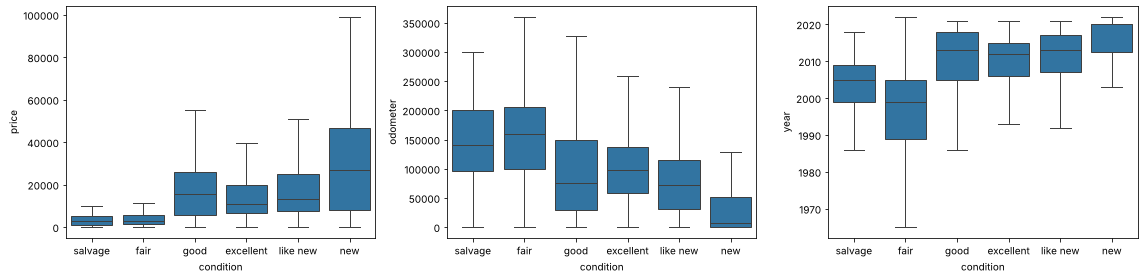

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['price', 'odometer', 'year']):
    sns.boxplot(x='condition', y=col, data=train, order=classes, showfliers=False, ax=ax)
plt.tight_layout()
pass

salvage и fair выделяются хорошо: дешевые (медиана около 3 тыс.), старые (2005 и 1999) и с большим пробегом (140-160 тыс. миль).
new тоже выделяется: 2020 год, пробег около 8 тыс., высокая цена. А вот good, excellent и like new почти одинаковые
(год 2012-2013, пробег 70-100 тыс.), ящики сильно перекрываются, так что ошибаться модель будет в основном на них.

Странно, что медианная цена good (15.6 тыс.) больше, чем у excellent (11 тыс.). Ниже разберемся, откуда это.

### Категориальные признаки по классам

Доли классов в зависимости от `title_status` (по строкам):

In [27]:
pd.crosstab(train['title_status'], train['condition'], normalize='index')[classes].round(3)

condition,salvage,fair,good,excellent,like new,new
title_status,,,,,,
clean,0.001,0.033,0.401,0.468,0.092,0.005
lien,0.019,0.094,0.302,0.377,0.170,0.038
missing,0.038,0.500,0.365,0.077,0.000,0.019
parts only,0.176,0.529,0.059,0.118,0.059,0.059
rebuilt,0.000,0.055,0.538,0.341,0.066,0.000
salvage,0.103,0.077,0.284,0.391,0.134,0.011


То же для типа продавца и медианная цена в каждой группе:

In [28]:
pd.crosstab(train['seller'], train['condition'], normalize='index')[classes].round(3)

condition,salvage,fair,good,excellent,like new,new
seller,,,,,,
dealer,0.00,0.001,0.391,0.532,0.073,0.003
owner,0.01,0.081,0.377,0.411,0.112,0.009


In [29]:
train.pivot_table(index='seller', columns='condition', values='price', aggfunc='median', observed=True)[classes]

condition,salvage,fair,good,excellent,like new,new
seller,,,,,,
dealer,6049.5,6997.0,22990.0,11999.0,11995.0,11995.0
owner,2900.0,2999.0,5725.0,9886.5,14500.0,34000.0


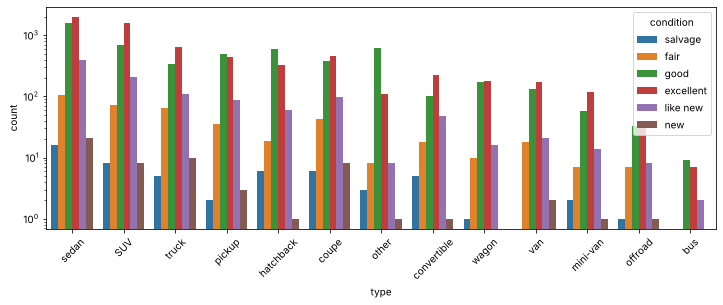

In [30]:
plt.figure(figsize=(12, 4))
sns.countplot(x='type', hue='condition', hue_order=classes,
              order=train['type'].value_counts().index, data=train)
plt.xticks(rotation=45)
plt.yscale('log')
pass

- При `title_status` missing и parts only больше половины машин fair или salvage. При этом документы salvage не значат
  condition = salvage: такие машины после ремонта часто продают как good или excellent.
- С типом продавца все интереснее. У частников медианная цена растет вместе с состоянием: 2.9, 3.0, 5.7, 9.9, 14.5, 34 тыс.
  А дилеры почти не пишут fair/salvage (0.1%) и дорогие машины у них часто помечены good (медиана 23 тыс. против 12 тыс. у excellent).
  То есть дилеры ставят состояние по своей логике, часто шаблонно. Получается, что сам целевой признак шумный, и выше какого-то
  качества тут не прыгнуть.
- По типам кузова распределение классов примерно одинаковое, везде больше всего excellent и good.

### Координаты

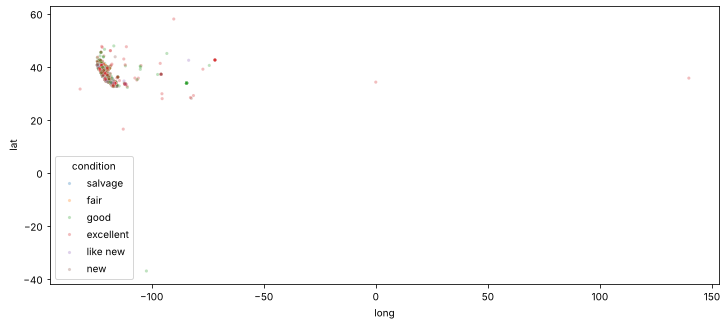

In [31]:
plt.figure(figsize=(12, 5))
sns.scatterplot(x='long', y='lat', hue='condition', hue_order=classes, data=train, alpha=0.3, s=10)
pass

Большая часть точек повторяет форму Калифорнии, но есть точки далеко за ее пределами. Особенно выделяется точка около (-84.4, 33.8) -
это Атланта. Посмотрим, что там:

In [32]:
atlanta = train[(train['lat'].round(1) == 33.8) & (train['long'].round(1) == -84.4)]
print('Объявлений с координатами Атланты:', len(atlanta))
print(atlanta['condition'].value_counts())
data_raw.loc[atlanta.index[:3], 'description'].str[:150].tolist()

Объявлений с координатами Атланты: 699
condition
good    699
Name: count, dtype: int64


['Carvana is the safer way to buy a car During these uncertain times, Carvana is dedicated to ensuring safety for all of our customers. In addition to o', 'Carvana is the safer way to buy a car During these uncertain times, Carvana is dedicated to ensuring safety for all of our customers. In addition to o', 'Carvana is the safer way to buy a car During these uncertain times, Carvana is dedicated to ensuring safety for all of our customers. In addition to o']

Это объявления Carvana (онлайн-продажа машин). Текст шаблонный, координаты - офис в Атланте, а не сама машина,
и у всех стоит good, независимо от года и пробега. Отчасти поэтому у good такая высокая цена.
Реального состояния машины эти объявления не отражают, в п. 4 удалим их вместе с остальными точками вне Калифорнии.

### Корреляционная матрица

In [33]:
corr_mat = train[numerical_columns].corr()
corr_mat

,price,year,cylinders,odometer,lat,long
price,1.000000,-0.006094,0.013320,0.001735,0.015707,-0.005697
year,-0.006094,1.000000,-0.231875,-0.143484,-0.039265,0.120873
cylinders,0.013320,-0.231875,1.000000,0.024262,0.014614,0.069708
odometer,0.001735,-0.143484,0.024262,1.000000,0.045805,-0.079582
lat,0.015707,-0.039265,0.014614,0.045805,1.000000,-0.377759
long,-0.005697,0.120873,0.069708,-0.079582,-0.377759,1.000000


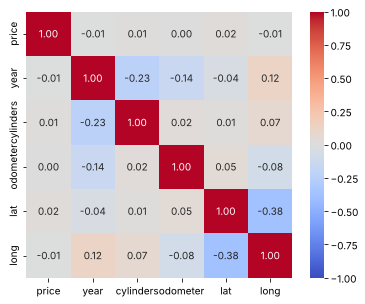

In [34]:
sns.heatmap(corr_mat, square=True, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
pass

Коэффициент Пирсона сильно портится выбросами, поэтому посчитаем еще корреляцию Спирмена (по рангам).
Заодно добавим целевой признак, заменив классы номерами от 0 (salvage) до 5 (new):

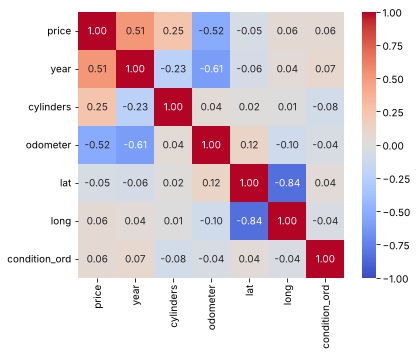

In [35]:
train_ord = train[numerical_columns].copy()
train_ord['condition_ord'] = train['condition'].map({c: i for i, c in enumerate(classes)}).astype(int)
corr_spearman = train_ord.corr(method='spearman')
sns.heatmap(corr_spearman, square=True, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
pass

Пары с |корреляцией Спирмена| > 0.3:

In [36]:
# в pandas 3 stack() не выкидывает NaN, поэтому dropna
corr_spearman.where(np.triu(np.abs(corr_spearman) > 0.3, k=1)).stack().dropna().sort_values()

lat    long       -0.840903
year   odometer   -0.606312
price  odometer   -0.524315
       year        0.513343
dtype: float64

По Пирсону почти все корреляции около нуля, но это из-за выбросов (одна цена в 1 млрд все портит).
По Спирмену видно то, что и ожидалось: чем новее машина, тем она дороже (0.51) и тем меньше пробег (-0.61),
чем больше пробег, тем дешевле (-0.52), машины с большим числом цилиндров немного дороже.
lat и long сильно коррелированы (-0.84), потому что Калифорния вытянута с северо-запада на юго-восток, к этому вернемся в п. 12.
С состоянием все признаки коррелируют слабо, ни один признак сам по себе состояние не определяет.

## 4. Выбросы

Сначала попробуем правило из лекции: выброс - значение вне $[Q_1-1.5\cdot{\rm IQR},\ Q_3+1.5\cdot{\rm IQR}]$.

In [37]:
for col in ['price', 'odometer', 'year']:
    Q1, Q3 = train[col].quantile([.25, .75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((train[col] < lower) | (train[col] > upper)).sum()
    print(f'{col:9s}: [{lower:10.0f}, {upper:10.0f}]  вне интервала: {n_out} ({n_out / N_train:.1%})')

price    : [    -18762,      47258]  вне интервала: 481 (3.1%)
odometer : [   -111680,     294208]  вне интервала: 166 (1.1%)
year     : [      1988,       2032]  вне интервала: 812 (5.3%)


Здесь это правило не очень подходит. Нижняя граница для цены и пробега отрицательная, так что нулевые цены оно не ловит,
зато выкидывает 3% нормальных дорогих машин (дороже 47 тыс.) и 5% машин старше 1988 года. Распределения слишком скошенные.

Поэтому делаем как на лекции через квантили, плюс немного здравого смысла:

- `price`: оставляем от 100 долларов до квантиля 0.995. Цены 0, 1, 10 долларов - это "цена по запросу" или заглушки дилеров;
- `odometer`: убираем все выше квантиля 0.995, а нижнюю границу не ставим, потому что у new пробег и должен быть около нуля;
- `lat`, `long`: оставляем только точки внутри прямоугольника вокруг Калифорнии (заодно уйдет Carvana);
- `year` не трогаем: старые машины настоящие, это коллекционные авто;
- пропуски выбросами не считаем, ими займемся в п. 5.

Пороги считаем по train, а применяем одно и то же правило и к train, и к test. Считаем, что модель работает только
с объявлениями с адекватными значениями (кривые цены и пробег на практике можно отсеивать тем же правилом).

In [38]:
price_lower = 100
price_upper = X_train['price'].quantile(0.995)
odometer_upper = X_train['odometer'].quantile(0.995)
LAT_MIN, LAT_MAX, LONG_MIN, LONG_MAX = 32.4, 42.1, -124.6, -114.0   # примерные границы Калифорнии

def is_outlier(X):
    return ((X['price'] < price_lower) | (X['price'] > price_upper) |
            (X['odometer'] > odometer_upper) |
            (X['lat'] < LAT_MIN) | (X['lat'] > LAT_MAX) |
            (X['long'] < LONG_MIN) | (X['long'] > LONG_MAX))

print(f'price: [{price_lower}, {price_upper:.0f}],  odometer <= {odometer_upper:.0f}')
print('Выбросов в train:', is_outlier(X_train).sum(), f'({is_outlier(X_train).mean():.1%})')
print('Выбросов в test: ', is_outlier(X_test).sum(),  f'({is_outlier(X_test).mean():.1%})')

price: [100, 85000],  odometer <= 358739
Выбросов в train: 1630 (10.6%)
Выбросов в test:  536 (10.4%)


Доля выбросов внутри каждого класса:

In [39]:
is_outlier(X_train).groupby(y_train, observed=True).mean().loc[classes].round(3)

condition
salvage      0.056
fair         0.024
good         0.154
excellent    0.075
like new     0.089
new          0.241
dtype: float64

In [40]:
mask_train = ~is_outlier(X_train)
mask_test  = ~is_outlier(X_test)
X_train, y_train = X_train[mask_train], y_train[mask_train]
X_test,  y_test  = X_test[mask_test],   y_test[mask_test]
train = X_train.join(y_train)

N_train, _ = X_train.shape
N_test,  _ = X_test.shape
N_train, N_test

(13790, 4604)

In [41]:
train.describe()

,price,year,cylinders,odometer,lat,long
count,13790.000000,13790.000000,10425.000000,13650.000000,13749.000000,13749.000000
mean,15739.988542,2008.300508,5.745899,101839.198168,36.259887,-119.793387
std,12809.145636,11.945803,1.615943,66648.648501,2.284271,1.880161
min,100.000000,1913.000000,3.000000,0.000000,32.474727,-124.284000
25%,6400.000000,2005.000000,4.000000,46291.750000,34.028900,-121.422557
50%,11995.000000,2011.000000,6.000000,97000.000000,36.621000,-119.788981
75%,21590.000000,2016.000000,8.000000,146185.750000,38.509785,-118.088300
max,85000.000000,2022.000000,12.000000,355795.000000,42.072703,-114.386096


In [42]:
train.groupby('condition', observed=True)[numerical_columns].median().loc[classes]

,price,year,cylinders,odometer,lat,long
condition,,,,,,
salvage,3050.0,2005.0,4.0,140000.0,36.630253,-120.103850
fair,3000.0,2000.0,6.0,158338.0,36.667750,-119.887519
good,13000.0,2012.0,6.0,90525.0,36.270000,-119.731400
excellent,11995.0,2012.0,6.0,99994.0,36.815675,-119.809638
like new,13958.5,2013.0,6.0,75503.0,35.582049,-119.699919
new,27500.0,2018.0,6.0,14018.5,34.901118,-119.799300


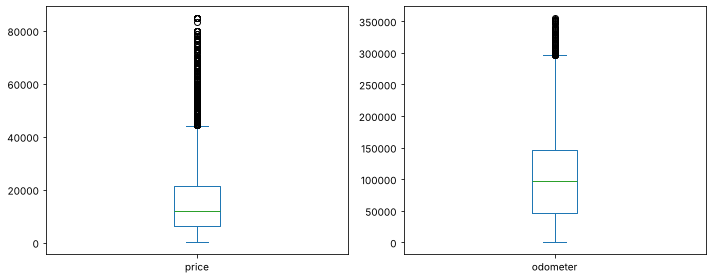

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
train['price'].plot(kind='box', ax=axes[0])
train['odometer'].plot(kind='box', ax=axes[1])
plt.tight_layout()
pass

Теперь ящики с усами нормальные, оставшиеся точки за усами - просто дорогие или сильно ездившие машины, а не ошибки.

Карта после очистки и диаграммы рассеивания (на случайных 3000 объектах, чтобы было что-то видно):

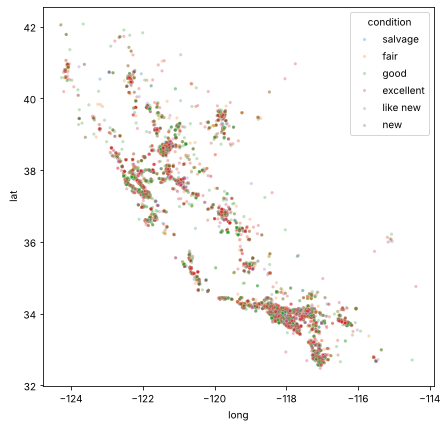

In [44]:
plt.figure(figsize=(7, 7))
sns.scatterplot(x='long', y='lat', hue='condition', hue_order=classes, data=train, alpha=0.3, s=10)
plt.gca().set_aspect('equal')
pass

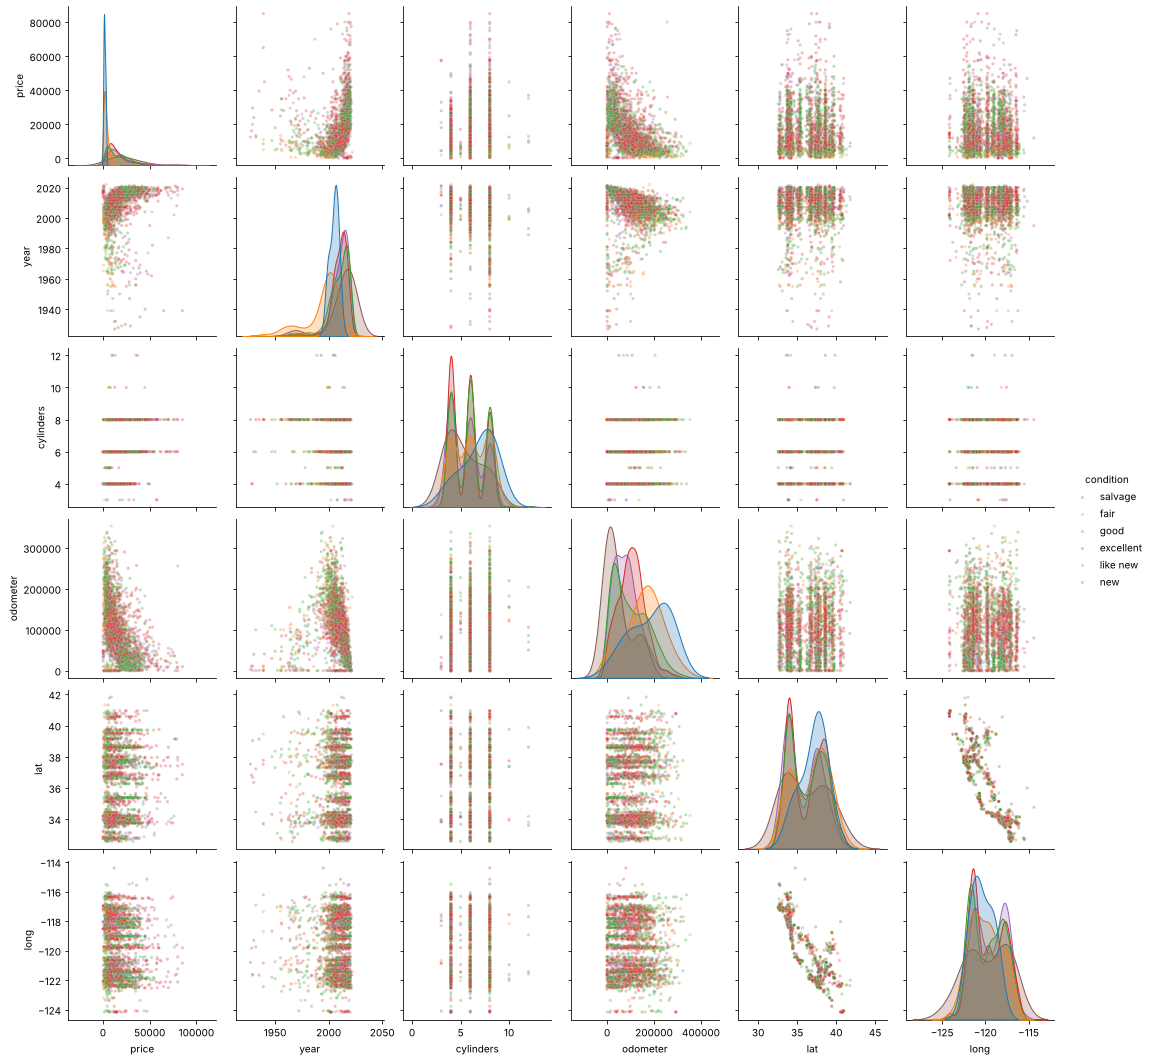

In [45]:
sns.pairplot(train[numerical_columns + ['condition']].sample(3000, random_state=0),
             hue='condition', hue_order=classes, diag_kind='kde', plot_kws={'alpha': 0.3, 's': 10},
             diag_kws={'common_norm': False})
pass

На карте остались только точки в Калифорнии (видно Сан-Франциско, Лос-Анджелес, Сан-Диего). На диаграммах рассеивания видны
зависимости цены от года и от пробега. По гистограммам на диагонали отличаются new (маленький пробег, новые) и fair/salvage
(большой пробег, старые), а три основных класса на всех картинках перемешаны, линейно их не разделить.

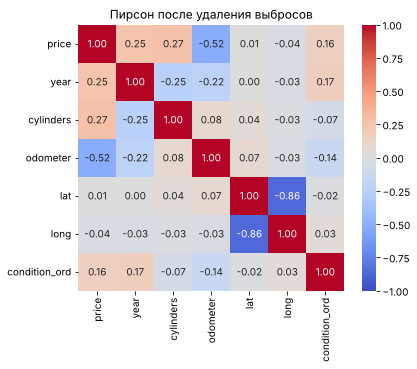

In [46]:
train_ord = train[numerical_columns].copy()
train_ord['condition_ord'] = train['condition'].map({c: i for i, c in enumerate(classes)}).astype(int)
corr_mat = train_ord.corr()
sns.heatmap(corr_mat, square=True, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Пирсон после удаления выбросов')
pass

In [47]:
pd.DataFrame({'Пирсон': corr_mat['condition_ord'], 'Спирмен': train_ord.corr(method='spearman')['condition_ord']}).drop('condition_ord').round(3)

,Пирсон,Спирмен
price,0.156,0.152
year,0.165,0.122
cylinders,-0.067,-0.075
odometer,-0.141,-0.084
lat,-0.019,-0.012
long,0.035,0.044


После удаления выбросов Пирсон и Спирмен стали примерно одинаковыми. Корреляция состояния с ценой и годом стала положительной (около 0.15),
но все равно слабой. Медианная цена good (13 тыс.) теперь почти такая же, как у excellent (12 тыс.).

Всего удалили около 10% объектов, причем больше всего из good (Carvana) и new (у новых машин дилеры часто ставят цену 0).

## 5. Пропущенные значения

In [48]:
pd.DataFrame({'train': X_train.isna().mean(), 'test': X_test.isna().mean()}).sort_values('train', ascending=False).round(3)

,train,test
size,0.584,0.598
drive,0.256,0.263
cylinders,0.244,0.241
paint_color,0.240,0.236
type,0.163,0.163
manufacturer,0.047,0.042
title_status,0.035,0.037
odometer,0.010,0.011
long,0.003,0.002
lat,0.003,0.002


Пропусков много: в `size` 58%, в `drive`, `cylinders`, `paint_color` около четверти. Удалять строки нельзя, останется мало данных,
удалять столбцы тоже не хочется, `cylinders` и `drive` явно полезные.

Числовые признаки заполняем медианой по train, как на лекции. Еще для каждого числового признака с пропусками добавляем
индикатор "значение было пропущено" (`add_indicator=True`), в первую очередь из-за `cylinders`, чтобы модель отличала
настоящие 6 цилиндров от подставленной медианы.

Категориальные заполнять самым частым значением, как на лекции, тут плохо: тогда, например, больше половины машин стали бы full-size.
К тому же сам пропуск что-то значит (частники и дилеры заполняют разные поля). Поэтому заполняем пропуски отдельным значением
'unknown', после one-hot оно само станет индикатором пропуска.

In [49]:
from sklearn.impute import SimpleImputer

imp_num = SimpleImputer(missing_values=np.nan, strategy='median', add_indicator=True)
imp_num.fit(X_train[numerical_columns])
imp_num.statistics_

array([ 1.19950000e+04,  2.01100000e+03,  6.00000000e+00,  9.70000000e+04,
        3.66210000e+01, -1.19788981e+02])

In [50]:
imp_cat = SimpleImputer(missing_values=np.nan, strategy='constant', fill_value='unknown')
imp_cat.fit(X_train[categorical_columns])

def impute(X):
    num = pd.DataFrame(imp_num.transform(X[numerical_columns]),
                       columns=imp_num.get_feature_names_out(), index=X.index)
    cat = pd.DataFrame(imp_cat.transform(X[categorical_columns]),
                       columns=categorical_columns, index=X.index)
    return num, cat

X_train_num, X_train_cat = impute(X_train)
X_test_num,  X_test_cat  = impute(X_test)
X_train_num.isna().sum().sum(), X_train_cat.isna().sum().sum(), X_test_num.isna().sum().sum(), X_test_cat.isna().sum().sum()

(np.int64(0), np.int64(0), np.int64(0), np.int64(0))

In [51]:
X_train_num.head()

,price,year,cylinders,odometer,lat,long,missingindicator_cylinders,missingindicator_odometer,missingindicator_lat,missingindicator_long
45432,31481.0,2019.0,6.0,28289.0,34.264798,-119.246834,0.0,0.0,0.0,0.0
45630,18810.0,2017.0,4.0,58741.0,34.264798,-119.246834,0.0,0.0,0.0,0.0
29804,28000.0,1991.0,6.0,134000.0,39.328000,-120.183300,0.0,0.0,0.0,0.0
4787,17950.0,2014.0,8.0,181367.0,36.905852,-119.794299,0.0,0.0,0.0,0.0
43854,15977.0,2014.0,4.0,58457.0,38.020942,-121.301919,0.0,0.0,0.0,0.0


## 6. Категориальные признаки

sklearn с категориальными признаками напрямую не работает, их нужно перевести в числа. Как на лекции, смотрим,
какие признаки бинарные:

In [52]:
X_train_cat.nunique()

seller           2
manufacturer    40
fuel             6
title_status     7
transmission     3
drive            4
size             5
type            14
paint_color     13
dtype: int64

Бинарный только `seller` (в нем нет пропусков, поэтому 'unknown' не появился), его заменяем одним признаком: dealer -> 0, owner -> 1.
Остальные кодируем one-hot: признак с $s$ значениями превращается в $s$ признаков из 0 и 1.
Оба варианта делает `OneHotEncoder(drop='if_binary')`, как на лекции.

`handle_unknown='ignore'` - на случай, если в тесте попадется значение, которого не было в train (тогда будут все нули).
Просто занумеровать значения (OrdinalEncoder) нельзя: марки не упорядочены, а kNN и логистическая регрессия
восприняли бы номера как числа.

In [53]:
from sklearn.preprocessing import OneHotEncoder

enc = OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False)
enc.fit(X_train_cat)

X_train_dummies = pd.DataFrame(enc.transform(X_train_cat), columns=enc.get_feature_names_out(), index=X_train.index)
X_test_dummies  = pd.DataFrame(enc.transform(X_test_cat),  columns=enc.get_feature_names_out(), index=X_test.index)
X_train_dummies.shape

(13790, 93)

In [54]:
X_train_dummies.iloc[:5, :12]

,seller_owner,manufacturer_acura,manufacturer_alfa-romeo,manufacturer_audi,manufacturer_bmw,manufacturer_buick,manufacturer_cadillac,manufacturer_chevrolet,manufacturer_chrysler,manufacturer_datsun,manufacturer_dodge,manufacturer_ferrari
45432,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
45630,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
29804,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4787,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
43854,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 7. Нормализация

kNN считает расстояния, поэтому масштаб признаков важен. Без нормализации расстояние определяли бы в основном
цена и пробег (десятки тысяч), а год, цилиндры и координаты почти не учитывались бы.

Стандартизируем числовые признаки (среднее 0, стандартное отклонение 1) по train. Dummy-признаки оставляем 0/1, как в Adult:
они и так в одном масштабе, а если стандартизировать редкий dummy (например, manufacturer_ferrari), он получит огромные значения
и будет перевешивать все остальное в расстоянии.

In [55]:
from sklearn.preprocessing import StandardScaler

scale_columns = numerical_columns    # индикаторы пропусков не трогаем
scaler = StandardScaler()
scaler.fit(X_train_num[scale_columns])

def scale(X_num):
    X_num = X_num.copy()
    X_num[scale_columns] = scaler.transform(X_num[scale_columns])
    return X_num

X_train_prep = pd.concat((scale(X_train_num), X_train_dummies), axis=1)
X_test_prep  = pd.concat((scale(X_test_num),  X_test_dummies),  axis=1)
X_train_prep.shape, X_test_prep.shape

((13790, 103), (4604, 103))

In [56]:
X_train_prep[imp_num.get_feature_names_out()].describe().round(3)

,price,year,cylinders,odometer,lat,long,missingindicator_cylinders,missingindicator_odometer,missingindicator_lat,missingindicator_long
count,13790.000,13790.000,13790.000,13790.000,13790.000,13790.000,13790.000,13790.00,13790.000,13790.000
mean,0.000,-0.000,-0.000,-0.000,0.000,0.000,0.244,0.01,0.003,0.003
std,1.000,1.000,1.000,1.000,1.000,1.000,0.430,0.10,0.054,0.054
min,-1.221,-7.978,-1.993,-1.535,-1.660,-2.392,0.000,0.00,0.000,0.000
25%,-0.729,-0.276,-1.283,-0.826,-0.978,-0.868,0.000,0.00,0.000,0.000
50%,-0.292,0.226,0.136,-0.072,0.158,0.002,0.000,0.00,0.000,0.000
75%,0.457,0.645,0.136,0.662,0.981,0.904,0.000,0.00,0.000,0.000
max,5.407,1.147,4.394,3.831,2.548,2.880,1.000,1.00,1.000,1.000


Проверим, что нормализация правда нужна:

In [57]:
from sklearn.neighbors import KNeighborsClassifier

X_train_raw = pd.concat((X_train_num, X_train_dummies), axis=1)
X_test_raw  = pd.concat((X_test_num,  X_test_dummies),  axis=1)

knn = KNeighborsClassifier(n_neighbors=10).fit(X_train_raw, y_train)
print('Без нормализации: ошибка на тесте =', round(np.mean(knn.predict(X_test_raw) != y_test), 4))
knn = KNeighborsClassifier(n_neighbors=10).fit(X_train_prep, y_train)
print('С нормализацией:  ошибка на тесте =', round(np.mean(knn.predict(X_test_prep) != y_test), 4))

Без нормализации: ошибка на тесте = 0.444
С нормализацией:  ошибка на тесте = 0.3334


С нормализацией ошибка 33% вместо 44%. Без нее kNN по сути искал соседей только по цене и пробегу.

Итоговая матрица признаков:

In [58]:
X_train_prep.head()

,price,year,cylinders,odometer,lat,long,missingindicator_cylinders,missingindicator_odometer,missingindicator_lat,missingindicator_long,seller_owner,manufacturer_acura,manufacturer_alfa-romeo,manufacturer_audi,manufacturer_bmw,...,type_van,type_wagon,paint_color_black,paint_color_blue,paint_color_brown,paint_color_custom,paint_color_green,paint_color_grey,paint_color_orange,paint_color_purple,paint_color_red,paint_color_silver,paint_color_unknown,paint_color_white,paint_color_yellow
45432,1.228933,0.895702,0.136317,-1.108466,-0.875174,0.291131,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
45630,0.239682,0.728273,-1.282945,-0.649221,-0.875174,0.291131,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
29804,0.957164,-1.448302,0.136317,0.485756,1.344677,-0.207706,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4787,0.172540,0.477130,1.555579,1.200096,0.282739,-0.000493,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
43854,0.018504,0.477130,-1.282945,-0.653504,0.771626,-0.803574,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [59]:
feature_names = X_train_prep.columns
X_train_np, X_test_np = X_train_prep.to_numpy(), X_test_prep.to_numpy()
y_train_np, y_test_np = y_train.to_numpy().astype(str), y_test.to_numpy().astype(str)
N_train, d = X_train_np.shape
N_train, d

(13790, 103)

## 8. Метод ближайших соседей

Почему начинаем с kNN:

- он ничего не предполагает про форму разделяющей поверхности, а по ящикам с усами видно, что зависимость от цены, года
  и пробега нелинейная;
- сразу работает с 6 классами;
- идея понятная: состояние машины такое же, как у большинства похожих машин (близкие год, пробег, цена, та же марка и кузов);
- гиперпараметр по сути один ($k$), его легко подобрать кросс-валидацией;
- после нормализации и one-hot все признаки числовые и в сопоставимом масштабе.

Минусы тоже есть: около 100 признаков (проклятие размерности), медленное предсказание (расстояния до всех ~14 тыс. объектов
train) и то, что при голосовании выигрывают большие классы.

Для начала $k = 10$, как на лекции:

In [60]:
knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train_np, y_train_np)

y_train_predict = knn.predict(X_train_np)
y_test_predict  = knn.predict(X_test_np)

## 9. Ошибки, матрицы рассогласования, подбор $k$

In [61]:
err_train = np.mean(y_train_np != y_train_predict)
err_test  = np.mean(y_test_np  != y_test_predict)
err_train, err_test

(np.float64(0.281145757795504), np.float64(0.3334057341442224))

Для сравнения классификатор, который всегда говорит excellent:

In [62]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent').fit(X_train_np, y_train_np)
1 - dummy.score(X_train_np, y_train_np), 1 - dummy.score(X_test_np, y_test_np)

(0.5039883973894126, 0.5052128583840139)

Матрица рассогласования на тесте (строки - истинный класс, столбцы - предсказанный):

In [63]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import balanced_accuracy_score, f1_score

print(confusion_matrix(y_test_np, y_test_predict, labels=classes))

[[   0    1    8   14    1    0]
 [   0    8   97   67    0    0]
 [   0   14 1046  609   12    0]
 [   0    5  257 1984   32    0]
 [   0    1   66  329   30    0]
 [   0    0    3   17    2    1]]


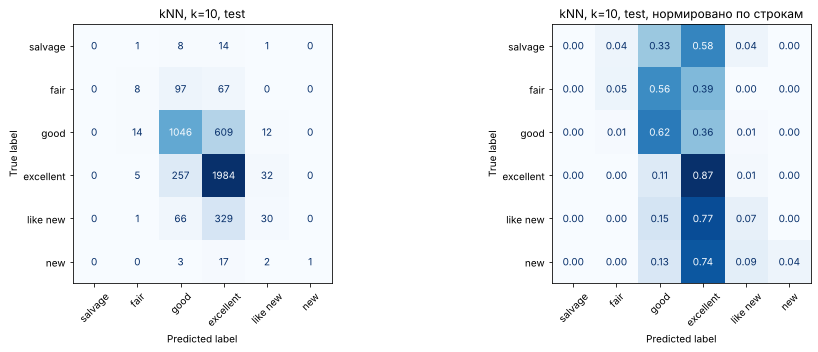

In [64]:
def plot_confusion(y_true, y_pred, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=classes, ax=axes[0],
                                            cmap='Blues', colorbar=False)
    axes[0].set_title(title)
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=classes, ax=axes[1], normalize='true',
                                            values_format='.2f', cmap='Blues', colorbar=False)
    axes[1].set_title(title + ', нормировано по строкам')
    for ax in axes:
        ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()

plot_confusion(y_test_np, y_test_predict, 'kNN, k=10, test')
pass

In [65]:
print(classification_report(y_test_np, y_test_predict, labels=classes, zero_division=0))

              precision    recall  f1-score   support

     salvage       0.00      0.00      0.00        24
        fair       0.28      0.05      0.08       172
        good       0.71      0.62      0.66      1681
   excellent       0.66      0.87      0.75      2278
    like new       0.39      0.07      0.12       426
         new       1.00      0.04      0.08        23

    accuracy                           0.67      4604
   macro avg       0.51      0.28      0.28      4604
weighted avg       0.63      0.67      0.63      4604



kNN с $k=10$ ошибается в 33% случаев на тесте (у константного классификатора 50%), на train 28%, то есть немного переобучается.

По матрице видно, где ошибки. Больше всего путаются good и excellent, сотни объектов в обе стороны, как и ожидалось после п. 3.
like new почти всегда уходит в excellent (полнота 7%), по признакам их почти не отличить. salvage и new модель почти не предсказывает:
среди 10 соседей редкий класс почти никогда не набирает большинство. fair угадывается только в 5% случаев, обычно его путают с good.

Accuracy 67% получается за счет двух больших классов, macro-F1 всего 0.28.

### Подбор $k$

Перебираем только нечетные $k$, потому что при четных голоса чаще делятся поровну. $k$ подбираем 5-кратной кросс-валидацией
на train (`GridSearchCV`). Заодно для каждого $k$ считаем ошибку на train и test, чтобы посмотреть на переобучение
(в выборе $k$ тест не участвует).

In [66]:
from sklearn.model_selection import GridSearchCV

k_arr = np.array([1, 3, 5, 7, 9, 11, 15, 21, 25, 31, 41, 51, 71, 101])
grid = GridSearchCV(KNeighborsClassifier(), param_grid={'n_neighbors': k_arr}, cv=5, n_jobs=-1)
grid.fit(X_train_np, y_train_np)

best_cv_err = 1 - grid.best_score_
best_n_neighbors = grid.best_params_['n_neighbors']
print(best_cv_err, best_n_neighbors)

0.33415518491660623 51


In [67]:
err_cv  = 1 - grid.cv_results_['mean_test_score']
std_cv  = grid.cv_results_['std_test_score']
err_train_arr, err_test_arr, bacc_test_arr = [], [], []
for k in k_arr:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train_np, y_train_np)
    y_pred = model.predict(X_test_np)
    err_train_arr.append(np.mean(model.predict(X_train_np) != y_train_np))
    err_test_arr.append(np.mean(y_pred != y_test_np))
    bacc_test_arr.append(balanced_accuracy_score(y_test_np, y_pred))

pd.DataFrame({'k': k_arr, 'err_train': err_train_arr, 'err_cv': err_cv, 'std_cv': std_cv, 'err_test': err_test_arr,
              'balanced_acc_test': bacc_test_arr}).set_index('k').round(4)

,err_train,err_cv,std_cv,err_test,balanced_acc_test
k,,,,,
1,0.0011,0.3889,0.0079,0.3701,0.3388
3,0.2101,0.3556,0.0081,0.3404,0.3146
5,0.2472,0.3466,0.0064,0.3395,0.2945
7,0.2645,0.3403,0.0034,0.3401,0.2807
9,0.2752,0.3400,0.0034,0.3377,0.2838
11,0.2844,0.3370,0.0030,0.3358,0.2730
15,0.2942,0.3361,0.0058,0.3330,0.2701
21,0.3020,0.3347,0.0045,0.3282,0.2607
25,0.3086,0.3352,0.0072,0.3291,0.2593


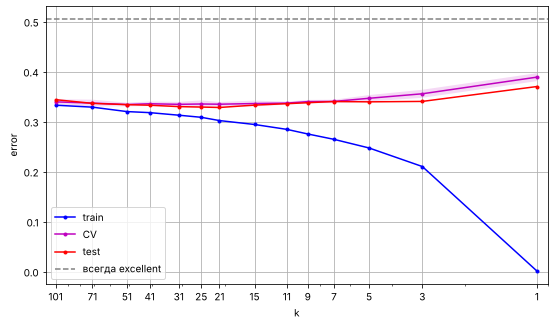

In [68]:
plt.figure(figsize=(9, 5))
plt.plot(k_arr, err_train_arr, 'b.-', label='train')
plt.plot(k_arr, err_cv, 'm.-', label='CV')
plt.fill_between(k_arr, err_cv - std_cv, err_cv + std_cv, alpha=0.15, facecolor='m')
plt.plot(k_arr, err_test_arr, 'r.-', label='test')
plt.axhline(1 - dummy.score(X_test_np, y_test_np), color='gray', ls='--', label='всегда excellent')
plt.xscale('log')
plt.xlim([max(k_arr) * 1.1, 0.9])     # как на лекции, k уменьшается слева направо
plt.xticks(k_arr, k_arr)
plt.xlabel('k')
plt.ylabel('error')
plt.legend()
plt.grid()
pass

При $k = 1$ ошибка на train почти 0 (каждый объект сам себе ближайший сосед), а на CV и тесте самая большая (37-39%) - переобучение.
При $k = 101$ ошибки снова растут, модель слишком сглаженная - недообучение.

Минимум ошибки на CV при $k = 51$ (33.4%), но кривая почти плоская от 15 до 51: разница около 0.2%, а разброс по фолдам 0.3-0.7%.
То есть все $k$ в этом диапазоне примерно одинаковые. Ошибка на тесте ведет себя так же, как на CV, значит кросс-валидация
оценивает качество нормально. А вот balanced accuracy с ростом $k$ падает: чем больше соседей, тем сильнее перевешивают большие классы.

Формально лучшее $k = 51$, его и берем.

In [69]:
knn = KNeighborsClassifier(n_neighbors=best_n_neighbors).fit(X_train_np, y_train_np)
y_train_predict = knn.predict(X_train_np)
y_test_predict  = knn.predict(X_test_np)

err_train = np.mean(y_train_np != y_train_predict)
err_test  = np.mean(y_test_np  != y_test_predict)
print(f'k = {best_n_neighbors}:  err_train = {err_train:.4f},  err_test = {err_test:.4f}')

k = 51:  err_train = 0.3200,  err_test = 0.3338


In [70]:
print(confusion_matrix(y_test_np, y_test_predict, labels=classes))

[[   0    0   13   11    0    0]
 [   0    0  114   58    0    0]
 [   0    0  989  691    1    0]
 [   0    0  198 2076    4    0]
 [   0    0   40  384    2    0]
 [   0    0    2   21    0    0]]


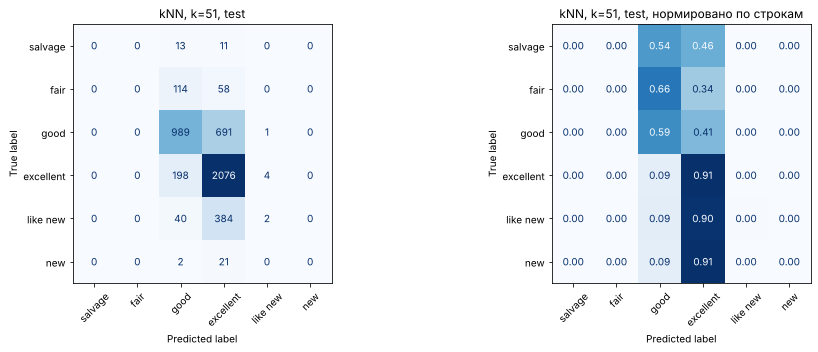

In [71]:
plot_confusion(y_test_np, y_test_predict, f'kNN, k={best_n_neighbors}, test')
pass

In [72]:
print(classification_report(y_test_np, y_test_predict, labels=classes, zero_division=0))

              precision    recall  f1-score   support

     salvage       0.00      0.00      0.00        24
        fair       0.00      0.00      0.00       172
        good       0.73      0.59      0.65      1681
   excellent       0.64      0.91      0.75      2278
    like new       0.29      0.00      0.01       426
         new       0.00      0.00      0.00        23

    accuracy                           0.67      4604
   macro avg       0.28      0.25      0.24      4604
weighted avg       0.61      0.67      0.61      4604



Попробуем еще взвешивать соседей по расстоянию (`weights='distance'`):

In [73]:
knn_w = KNeighborsClassifier(n_neighbors=best_n_neighbors, weights='distance').fit(X_train_np, y_train_np)
print('err_train =', np.mean(knn_w.predict(X_train_np) != y_train_np), ' err_test =', np.mean(knn_w.predict(X_test_np) != y_test_np))

err_train = 0.0010877447425670776  err_test = 0.3216768027801911


С $k = 51$ ошибка на тесте 33.4%, на train 32%, переобучения почти нет. Но по матрице видно, что модель фактически
предсказывает только good и excellent, редкие классы пропали совсем. Если важно находить именно редкие состояния
(например, битые машины), лучше взять $k$ поменьше, например 15 (ошибка та же, balanced accuracy выше), или бороться с дисбалансом (п. 11).

С весами по расстоянию ошибка на тесте 32.2%, но на train становится нулевой: обучающий объект находит сам себя
на нулевом расстоянии, и его голос перевешивает всех.

## 10. Другие классификаторы

Сравним с другими методами из курса: ошибка на train и test, а также balanced accuracy и macro-F1 на тесте.

In [74]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn import ensemble

results = pd.DataFrame(columns=['err_train', 'err_test', 'balanced_acc_test', 'macro_F1_test'])

def evaluate(name, model, X_tr=X_train_np, X_te=X_test_np, y_tr=y_train_np, y_te=y_test_np, fit=True, **fit_params):
    if fit:
        model.fit(X_tr, y_tr, **fit_params)
    y_tr_pred, y_te_pred = model.predict(X_tr), model.predict(X_te)
    results.loc[name] = (np.mean(y_tr_pred != y_tr), np.mean(y_te_pred != y_te),
                         balanced_accuracy_score(y_te, y_te_pred), f1_score(y_te, y_te_pred, average='macro'))
    return y_te_pred

evaluate('Dummy (всегда excellent)', dummy, fit=False)
evaluate(f'kNN, k={best_n_neighbors}', knn, fit=False)
pass

Логистическая регрессия:

In [75]:
evaluate('Logistic Regression', LogisticRegression(max_iter=3000))
results

,err_train,err_test,balanced_acc_test,macro_F1_test
Dummy (всегда excellent),0.503988,0.505213,0.166667,0.110336
"kNN, k=51",0.320015,0.333840,0.250727,0.235475
Logistic Regression,0.335388,0.340356,0.308972,0.321366


SVC с rbf ядром, параметры по умолчанию (перебор $C$ и $\gamma$ на таком объеме считался бы очень долго):

In [76]:
evaluate('SVC (rbf)', SVC())
results

,err_train,err_test,balanced_acc_test,macro_F1_test
Dummy (всегда excellent),0.503988,0.505213,0.166667,0.110336
"kNN, k=51",0.320015,0.333840,0.250727,0.235475
Logistic Regression,0.335388,0.340356,0.308972,0.321366
SVC (rbf),0.280348,0.314726,0.265100,0.253038


Деревья и ансамбли:

In [77]:
evaluate('Decision Tree', DecisionTreeClassifier(random_state=42))
evaluate('Decision Tree, max_depth=10', DecisionTreeClassifier(max_depth=10, random_state=42))
rf = ensemble.RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=42)
y_test_predict_rf = evaluate('Random Forest', rf)
evaluate('Extra Trees', ensemble.ExtraTreesClassifier(n_estimators=500, n_jobs=-1, random_state=42))
evaluate('AdaBoost', ensemble.AdaBoostClassifier(n_estimators=200, random_state=42))
gbt = ensemble.GradientBoostingClassifier(n_estimators=200, random_state=42)
y_test_predict_gbt = evaluate('Gradient Boosting', gbt)
results

,err_train,err_test,balanced_acc_test,macro_F1_test
Dummy (всегда excellent),0.503988,0.505213,0.166667,0.110336
"kNN, k=51",0.320015,0.333840,0.250727,0.235475
Logistic Regression,0.335388,0.340356,0.308972,0.321366
SVC (rbf),0.280348,0.314726,0.265100,0.253038
Decision Tree,0.001088,0.324283,0.410133,0.407714
"Decision Tree, max_depth=10",0.260044,0.316247,0.351567,0.379079
Random Forest,0.001088,0.270200,0.343499,0.376586
Extra Trees,0.001088,0.296699,0.320529,0.342623
AdaBoost,0.351342,0.354040,0.327452,0.336372
Gradient Boosting,0.223568,0.289531,0.416838,0.443615


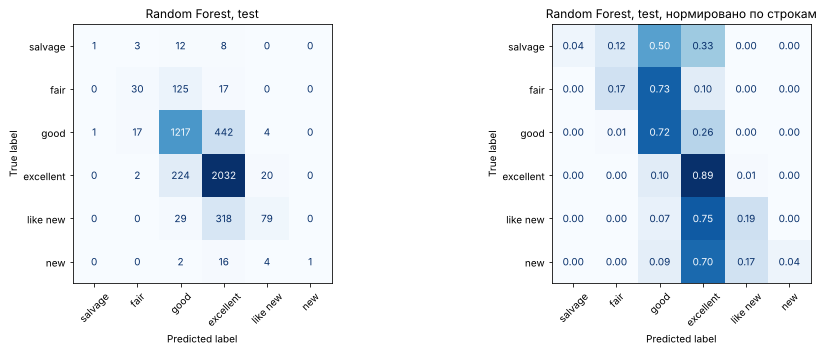

In [78]:
plot_confusion(y_test_np, y_test_predict_rf, 'Random Forest, test')
pass

### Важность признаков (Random Forest)

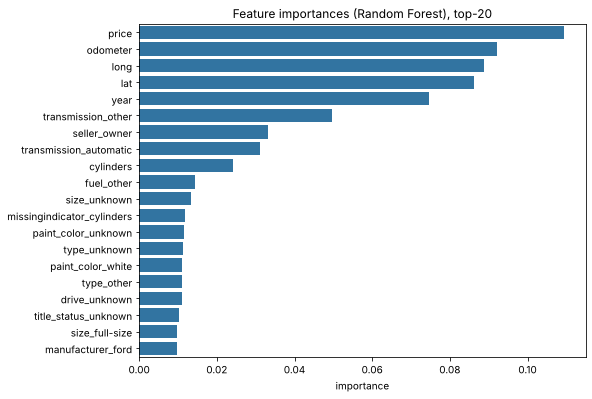

In [79]:
importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
sns.barplot(y=importances.index[:20], x=importances.iloc[:20], orient='h')
plt.title('Feature importances (Random Forest), top-20')
plt.xlabel('importance')
plt.ylabel('')
pass

Лучше всех по доле ошибок случайный лес: 27.0% на тесте (kNN 33.4%, константа 50.5%). На train у него ошибка 0.1%,
деревья запоминают выборку, но за счет усреднения 500 деревьев на тесте все равно лучше всех.

Градиентный бустинг по ошибке чуть хуже (29.0%), зато у него лучшие balanced accuracy (0.42) и macro-F1 (0.44),
то есть он лучше находит редкие классы. Одно дерево без ограничения глубины сильно переобучилось (ошибка 32%),
но по macro-F1 неплохое, потому что не боится предсказывать редкие классы.

Логистическая регрессия (34.0%) и AdaBoost (35.4%) хуже kNN, зависимость явно нелинейная. SVC (31.5%) немного лучше kNN,
но считается гораздо дольше. kNN по ошибке где-то посередине, а по macro-F1 хуже всех, кроме константного классификатора.

По важности признаков в лесу на первых местах цена, пробег, координаты и год. То, что важны координаты, не значит,
что состояние зависит от района: скорее координаты определяют конкретного дилера, а каждый дилер ставит состояние по-своему.
Из-за этого же важны `seller_owner` и `transmission_other` (other массово проставляют дилерские сервисы выгрузки объявлений).

## 11. Несбалансированность классов

Доля ошибок поощряет модель выбирать большие классы: new и salvage по 0.5% выборки, на общую ошибку они почти не влияют.
Поэтому здесь в основном смотрим на balanced accuracy и macro-F1.

Пробуем три способа:

1. Веса классов (`class_weight='balanced'`): ошибка на объекте класса штрафуется с весом, обратно пропорциональным размеру класса.
   У градиентного бустинга такого параметра нет, поэтому передаем такие же веса через `sample_weight`.
2. Oversampling: у kNN весов классов нет, поэтому просто размножаем объекты маленьких классов в train, пока все классы
   не станут размером с самый большой.
3. Укрупнение классов: salvage + fair -> fair/salvage, like new + new -> like new/new.

In [80]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.utils import resample

results_imb = pd.DataFrame(columns=results.columns)

def evaluate_imb(name, model, X_tr=X_train_np, y_tr=y_train_np, X_te=X_test_np, y_te=y_test_np, **fit_params):
    model.fit(X_tr, y_tr, **fit_params)
    y_te_pred = model.predict(X_te)
    # err_train считаем на исходном train, а не на размноженном
    results_imb.loc[name] = (np.mean(model.predict(X_train_np) != y_train_np), np.mean(y_te_pred != y_te),
                             balanced_accuracy_score(y_te, y_te_pred), f1_score(y_te, y_te_pred, average='macro'))
    return y_te_pred

# 1. веса классов
evaluate_imb('Logistic Regression, balanced', LogisticRegression(max_iter=3000, class_weight='balanced'))
y_pred_rf_bal = evaluate_imb('Random Forest, balanced',
                             ensemble.RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                                             class_weight='balanced_subsample', n_jobs=-1, random_state=42))
y_pred_gbt_bal = evaluate_imb('Gradient Boosting, balanced', ensemble.GradientBoostingClassifier(n_estimators=200, random_state=42),
                              sample_weight=compute_sample_weight('balanced', y_train_np))
results_imb

,err_train,err_test,balanced_acc_test,macro_F1_test
"Logistic Regression, balanced",0.518347,0.534970,0.498060,0.317830
"Random Forest, balanced",0.107977,0.315161,0.476419,0.435440
"Gradient Boosting, balanced",0.336186,0.396612,0.545651,0.410332


In [81]:
# 2. oversampling
n_max = pd.Series(y_train_np).value_counts().max()
X_over, y_over = [], []
for c in classes:
    X_c, y_c = X_train_np[y_train_np == c], y_train_np[y_train_np == c]
    X_c, y_c = resample(X_c, y_c, replace=True, n_samples=n_max, random_state=42) if len(y_c) < n_max else (X_c, y_c)
    X_over.append(X_c); y_over.append(y_c)
X_over, y_over = np.vstack(X_over), np.concatenate(y_over)
print('После oversampling:', X_over.shape, pd.Series(y_over).value_counts().to_dict())

y_pred_knn_over = evaluate_imb(f'kNN, k={best_n_neighbors}, oversampling', KNeighborsClassifier(n_neighbors=best_n_neighbors), X_tr=X_over, y_tr=y_over)
evaluate_imb('Random Forest, oversampling', ensemble.RandomForestClassifier(n_estimators=500, min_samples_leaf=3, n_jobs=-1, random_state=42), X_tr=X_over, y_tr=y_over)
results_imb

После oversampling: (41040, 103) {'salvage': 6840, 'fair': 6840, 'good': 6840, 'excellent': 6840, 'like new': 6840, 'new': 6840}


,err_train,err_test,balanced_acc_test,macro_F1_test
"Logistic Regression, balanced",0.518347,0.534970,0.498060,0.317830
"Random Forest, balanced",0.107977,0.315161,0.476419,0.435440
"Gradient Boosting, balanced",0.336186,0.396612,0.545651,0.410332
"kNN, k=51, oversampling",0.478608,0.528671,0.432907,0.299591
"Random Forest, oversampling",0.085569,0.303649,0.474600,0.457587


Те же модели без борьбы с дисбалансом:

In [82]:
results.loc[[f'kNN, k={best_n_neighbors}', 'Logistic Regression', 'Random Forest', 'Gradient Boosting']]

,err_train,err_test,balanced_acc_test,macro_F1_test
"kNN, k=51",0.320015,0.333840,0.250727,0.235475
Logistic Regression,0.335388,0.340356,0.308972,0.321366
Random Forest,0.001088,0.270200,0.343499,0.376586
Gradient Boosting,0.223568,0.289531,0.416838,0.443615


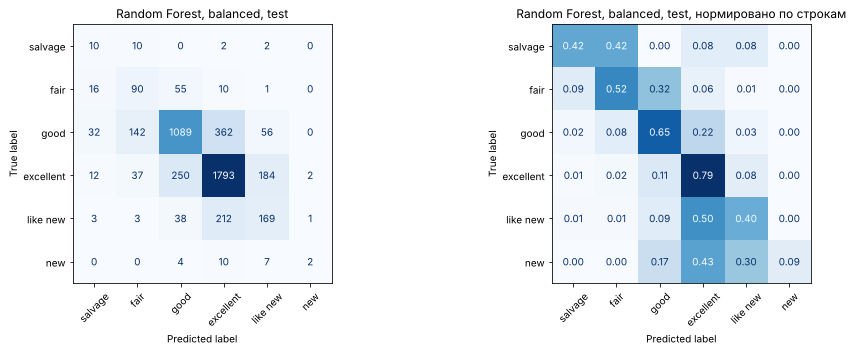

In [83]:
plot_confusion(y_test_np, y_pred_rf_bal, 'Random Forest, balanced, test')
pass

Веса классов помогают редким классам: у леса balanced accuracy выросла с 0.34 до 0.48, macro-F1 с 0.38 до 0.44,
у бустинга balanced accuracy 0.55, у логистической регрессии с 0.31 до 0.50. Но доля ошибок при этом растет
(у леса с 27% до 31.5%, у логистической регрессии до 53%), потому что часть объектов больших классов теперь уходит в редкие.
По матрице леса это хорошо видно: полнота salvage стала 42%, fair 52%, like new 40%, но часть good и excellent
теперь ошибочно попадает в fair и like new.

Oversampling для kNN с $k = 51$ сработал плохо (ошибка 53%). Каждый из примерно 65 объектов salvage скопирован около 100 раз,
и рядом с таким объектом все 51 соседей - его же копии. Вокруг нескольких редких объектов получаются "острова",
которые забирают себе объекты больших классов. Для леса oversampling дает примерно то же, что и веса.

Что выбрать, зависит от задачи: если нужна максимальная доля правильных ответов, с дисбалансом бороться не надо,
а если важно находить редкие состояния (например, salvage), лучше веса классов.

Укрупнение классов (4 класса вместо 6):

In [84]:
merge = {'salvage': 'fair/salvage', 'fair': 'fair/salvage', 'good': 'good', 'excellent': 'excellent',
         'like new': 'like new/new', 'new': 'like new/new'}
y_train_4 = pd.Series(y_train_np).map(merge).to_numpy()
y_test_4  = pd.Series(y_test_np).map(merge).to_numpy()
classes_4 = ['fair/salvage', 'good', 'excellent', 'like new/new']
pd.Series(y_train_4).value_counts(normalize=True).loc[classes_4].round(3)

fair/salvage    0.044
good            0.364
excellent       0.496
like new/new    0.096
Name: proportion, dtype: float64

In [85]:
results_4 = pd.DataFrame(columns=['err_test', 'balanced_acc_test', 'macro_F1_test'])
for name, model in [(f'kNN, k={best_n_neighbors}', KNeighborsClassifier(n_neighbors=best_n_neighbors)),
                    ('Random Forest', ensemble.RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=42)),
                    ('Random Forest, balanced', ensemble.RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                                class_weight='balanced_subsample', n_jobs=-1, random_state=42))]:
    y_pred = model.fit(X_train_np, y_train_4).predict(X_test_np)
    results_4.loc[name] = (np.mean(y_pred != y_test_4), balanced_accuracy_score(y_test_4, y_pred), f1_score(y_test_4, y_pred, average='macro'))
results_4

,err_test,balanced_acc_test,macro_F1_test
"kNN, k=51",0.333840,0.377371,0.356266
Random Forest,0.269548,0.502301,0.537795
"Random Forest, balanced",0.302129,0.625700,0.594526


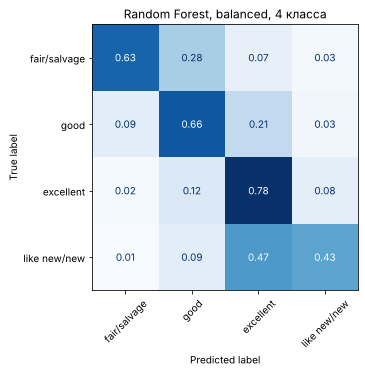

In [86]:
ConfusionMatrixDisplay.from_predictions(y_test_4, y_pred, labels=classes_4, normalize='true',
                                        values_format='.2f', cmap='Blues', colorbar=False)
plt.title('Random Forest, balanced, 4 класса')
plt.xticks(rotation=45)
pass

С 4 классами задача заметно проще: у леса при той же ошибке 27% balanced accuracy 0.50 вместо 0.34, а с весами 0.63 (macro-F1 0.59).
fair/salvage угадывается в 63% случаев, like new/new в 43%, хотя по отдельности salvage и new почти не находились.
Да и по смыслу такая шкала нормальная: где кончается fair и начинается salvage, или like new и new, продавцы все равно решают на глаз.

## 12. Удаление коррелированных признаков

Зачем это делать. Сильно коррелированные признаки несут почти одну и ту же информацию. В kNN она учитывается
в расстоянии два раза, и это направление получает больший вес, чем остальные. В линейных моделях появляется
мультиколлинеарность, коэффициенты становятся неустойчивыми и их сложно интерпретировать. Ну и лишние признаки
увеличивают размерность и время работы.

Ищем пары с |корреляцией| > 0.7 по всей итоговой матрице признаков (вместе с dummy):

In [87]:
corr_all = X_train_prep.corr()
high_corr = corr_all.where(np.triu(np.abs(corr_all) > 0.7, k=1)).stack().dropna().sort_values(key=np.abs, ascending=False)
high_corr

missingindicator_lat    missingindicator_long    1.00000
lat                     long                    -0.86452
transmission_automatic  transmission_other      -0.70692
dtype: float64

Таких пар всего три. Индикаторы пропуска lat и long совпадают полностью (координаты всегда пропущены вместе).
lat и long коррелированы из-за формы штата (-0.86). transmission_automatic и transmission_other (-0.71) - у коробки всего три значения
и manual редкий, поэтому эти два dummy почти взаимоисключающие.

Из каждой пары выкидываем второй признак:

In [88]:
to_drop = sorted(set(j for i, j in high_corr.index))
print('Удаляем:', to_drop)
keep = [c for c in feature_names if c not in to_drop]
X_train_red, X_test_red = X_train_prep[keep].to_numpy(), X_test_prep[keep].to_numpy()
X_train_red.shape

Удаляем: ['long', 'missingindicator_long', 'transmission_other']


(13790, 100)

In [89]:
results_red = pd.DataFrame(columns=['err_train', 'err_test', 'balanced_acc_test', 'macro_F1_test'])
for name, make_model in [(f'kNN, k={best_n_neighbors}', lambda: KNeighborsClassifier(n_neighbors=best_n_neighbors)),
                         ('Logistic Regression', lambda: LogisticRegression(max_iter=3000)),
                         ('Random Forest', lambda: ensemble.RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=42))]:
    for suffix, X_tr, X_te in [('все признаки', X_train_np, X_test_np), ('без коррелированных', X_train_red, X_test_red)]:
        model = make_model().fit(X_tr, y_train_np)
        y_pred = model.predict(X_te)
        results_red.loc[f'{name}, {suffix}'] = (np.mean(model.predict(X_tr) != y_train_np), np.mean(y_pred != y_test_np),
                                                balanced_accuracy_score(y_test_np, y_pred), f1_score(y_test_np, y_pred, average='macro'))
results_red

,err_train,err_test,balanced_acc_test,macro_F1_test
"kNN, k=51, все признаки",0.320015,0.333840,0.250727,0.235475
"kNN, k=51, без коррелированных",0.322915,0.337750,0.250293,0.234888
"Logistic Regression, все признаки",0.335388,0.340356,0.308972,0.321366
"Logistic Regression, без коррелированных",0.333865,0.340356,0.310030,0.322786
"Random Forest, все признаки",0.001088,0.270200,0.343499,0.376586
"Random Forest, без коррелированных",0.001088,0.278019,0.337684,0.368142


Почти ничего не изменилось: у kNN и логистической регрессии ошибка поменялась на десятые доли процента, у леса чуть выросла (27.0% -> 27.8%).
Это понятно: удалили всего 3 признака из 103, так что "двойной вес" в kNN был небольшой; логистическая регрессия в sklearn
по умолчанию с регуляризацией и к мультиколлинеарности не так чувствительна; а лесу `long` все-таки дает информацию,
которой нет в `lat` (корреляция -0.86 это не полное совпадение, а пара координат указывает на конкретного дилера).
Но выкинуть полный дубль вроде missingindicator_long все равно имеет смысл, модель проще, качество то же.

## 13. Выводы

1. Решали задачу классификации состояния машины (6 классов) по объявлениям craigslist в Калифорнии. После удаления дубликатов
   осталось 20.5 тыс. объявлений, после удаления выбросов 18.4 тыс.
2. Данные пришлось много чистить. У трети объявлений нет состояния, около 38% оставшихся - повторные публикации тех же машин
   (без их удаления ошибка на тесте была бы занижена на 6-7%), около 10% выбросов (цены 0 и 1 млрд, пробег 10 млн миль,
   координаты вне штата, шаблонные объявления Carvana), много пропусков (в `size` 58%). Пропуски в категориальных признаках
   заполняли отдельным значением unknown.
3. Для kNN нормализация обязательна: без нее ошибка 44%, с ней 33%.
4. Для kNN по кросс-валидации лучшее $k = 51$, ошибка на тесте 33.4% (на train 32%), у константного классификатора 50.5%.
   При $k$ от 15 до 51 ошибка почти не меняется, при маленьких $k$ модель переобучается. Почти все ошибки - путаница
   между good, excellent и like new, редкие классы kNN почти не предсказывает.
5. Лучше всего работают ансамбли деревьев: случайный лес 27.0% ошибок, градиентный бустинг 29.0%, но у бустинга лучшие
   balanced accuracy и macro-F1. Логистическая регрессия и AdaBoost хуже kNN.
6. Дисбаланс классов сильно мешает. Веса классов повышают balanced accuracy (у леса с 0.34 до 0.48), но общая ошибка растет.
   Oversampling с kNN работает плохо. Если объединить классы до 4, balanced accuracy получается 0.63.
7. Удаление коррелированных признаков (`long`, дублирующий индикатор пропуска, `transmission_other`) на качество почти не повлияло.
8. Основная проблема - шум в самом целевом признаке. Состояние пишет продавец, и разные продавцы (особенно дилеры) понимают
   шкалу по-разному: у частников цена растет вместе с состоянием, у дилеров нет. Поэтому даже лучшая модель ошибается примерно
   в каждом четвертом случае. Скорее всего, сильно помог бы текст объявления (`description`, например через TF-IDF), там бывают
   слова вроде "accident", "runs great", "needs work".